# Embico — модель по time-lapse видео эмбриона · v0.4
**Датасет:** Gomez et al. 2022 (704 видео, лицензия CC BY-NC-SA — только исследование/демо).

**Что нового по сравнению с v0.3**
1. **Аудит оригинала:** сверяем контрольные суммы архивов с Zenodo и смотрим файлы *внутри* архива без распаковки → понимаем, битые кадры есть в самом датасете или появились при распаковке.
2. **Полная чистка:** битые, пустые, почти пустые кадры, точные дубликаты (по содержимому), повтор времени, кадры без разметки, проверка ID пациенток.
3. **3 фокальные плоскости** (F-15, F0, F15) вместо одной — клетки, лежащие друг над другом, видны лучше.
4. **Две новые модели:** ConvNeXt-Tiny (сильнее EfficientNet-B0) и ConvNeXt-Tiny + BiGRU (смотрит на всё видео целиком).
5. **Умная склейка (HMM):** знает, как часто стадия сменяется на следующую и какие стадии обычно пропускаются (например, 2 → 4).
6. **Все метрики:** классификация (accuracy, precision, recall, F1), регрессия времени событий (MAE, RMSE, R², медиана), бинарный прогноз (AUROC с доверительным интервалом).
7. **Честное сравнение 5 вариантов** на одном и том же тесте (те же 141 видео, что в v0.3).
8. **Поправка смещения** модели перед флагами «вне нормы» и ранг вместо «голой» вероятности бластоцисты.



## 0. Настройки

In [1]:
import os, re, io, glob, json, random, time, copy, subprocess, hashlib, shutil
from collections import defaultdict
from multiprocessing import Pool
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import torchvision.transforms as T
from PIL import Image
import timm
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, r2_score)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

CFG = dict(
    data_root='/kaggle/input', work='/tmp/gomez', out_dir='/kaggle/working',
    zenodo='https://zenodo.org/records/7885222/files/',
    focal=['F-15', 'F0', 'F15'],                  # 3 фокуса -> 3 канала картинки (F0 = центральный)
    backbone='convnext_tiny.fb_in22k_ft_in1k', img_size=224, batch_size=48, epochs=10, lr=2e-4,
    train_every=2,                                 # каждую эпоху берём каждый 2-й кадр, но со сдвигом -> за 2 эпохи модель видит все кадры
    test_frac=0.2, val_frac=0.15, num_workers=4, seed=42,
    seq_epochs=40, seq_lr=1e-3, lambdas=[0.0, 0.25, 0.5, 1.0, 2.0],
    early_hours=72, observe_hours=110, n_boot=1000, model_version='timelapse-v0.4',
)
# Контрольные суммы (md5) с официальной страницы Zenodo
MD5 = {'embryo_dataset_annotations.tar.gz': 'c9b6e725a6c032b3f94d838580ac2e53',
       'embryo_dataset_time_elapsed.tar.gz': '01bd49e679cb19ec67172bbab5495fdc',
       'embryo_dataset.tar.gz': 'f8f7c72e40725331dd16d6d89b8e6c32',
       'embryo_dataset_F-15.tar.gz': '57169f763497fe28ef43e5857b15dc08',
       'embryo_dataset_F15.tar.gz': 'f436ecb9c532b138d95f5df45c313d61'}
ARCHIVES = [('embryo_dataset_annotations.tar.gz', 'meta'), ('embryo_dataset_time_elapsed.tar.gz', 'meta'),
            ('embryo_dataset.tar.gz', 'F0'), ('embryo_dataset_F-15.tar.gz', 'F-15'), ('embryo_dataset_F15.tar.gz', 'F15')]

# tHB (вылупление) встречается ~5 раз -> объединяем с tEB. Стало 15 стадий.
PHASES = ['tPB2','tPNa','tPNf','t2','t3','t4','t5','t6','t7','t8','t9+','tM','tSB','tB','tEB']
PIDX = {p: i for i, p in enumerate(PHASES)}; PIDX['tHB'] = PIDX['tEB']
K = len(PHASES)
KEY = ['t2', 't3', 't4', 't5', 't8', 'tSB', 'tB']   # ключевые события для главной метрики

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG['seed']); DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
os.makedirs(CFG['work'], exist_ok=True); os.makedirs(CFG['out_dir'], exist_ok=True)
print('device:', DEVICE, '| свободно на диске:', round(shutil.disk_usage(CFG['work']).free / 1e9), 'ГБ')

device: cuda | свободно на диске: 1126 ГБ


## 1. Аудит оригинального датасета (до распаковки)
Для каждого архива проверяем:
- **md5_ok** — совпадает ли контрольная сумма с Zenodo. Если нет, архив испорчен при скачивании/копировании → перекачать.
- **archive_ok** — читается ли архив до конца (не обрезан).
- **images** — сколько картинок *внутри* архива.
- **empty_images_0B** — сколько картинок внутри архива имеют размер 0 байт. Если > 0 — пустые файлы есть **в самом оригинальном датасете**, а не появились у нас.

In [2]:
def md5sum(path, chunk=1 << 24):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''): h.update(b)
    return h.hexdigest()

def get_archive(name):
    # Сначала ищем в Kaggle Input, иначе качаем с Zenodo
    hits = glob.glob(os.path.join(CFG['data_root'], '**', name), recursive=True)
    if hits: return hits[0]
    dst = os.path.join(CFG['work'], name)
    if not os.path.exists(dst) or os.path.getsize(dst) == 0:
        print('скачиваю с Zenodo:', name, '…'); t0 = time.time()
        subprocess.run(['curl', '-sL', '--retry', '5', '-o', dst, CFG['zenodo'] + name + '?download=1'], check=True)
        print(f'  готово за {(time.time() - t0) / 60:.1f} мин')
    return dst

def tar_listing(path):
    # Список файлов внутри архива без распаковки: (имя, размер в байтах)
    r = subprocess.run(['tar', '-tzvf', path], capture_output=True, text=True)
    rows = []
    for line in r.stdout.splitlines():
        p = line.split()
        if line.startswith('-') and len(p) >= 6: rows.append((p[-1], int(p[2])))
    return r.returncode == 0, pd.DataFrame(rows, columns=['name', 'size'])

ARCH, AUDIT, LISTING = {}, [], {}
for name, _ in ARCHIVES:
    p = get_archive(name); ARCH[name] = p
    ok, lst = tar_listing(p)
    img = lst[lst.name.str.lower().str.endswith(('.jpg', '.jpeg', '.png'))]; LISTING[name] = img
    AUDIT.append(dict(archive=name, size_gb=round(os.path.getsize(p) / 1e9, 2), md5_ok=md5sum(p) == MD5[name],
                      archive_ok=ok, files=len(lst), images=len(img), empty_images_0B=int((img['size'] == 0).sum())))
    print(AUDIT[-1])
AUDIT = pd.DataFrame(AUDIT); display(AUDIT)
AUDIT.to_csv(os.path.join(CFG['out_dir'], 'audit_archives.csv'), index=False)
if not AUDIT.md5_ok.all(): print('⚠️ Есть архивы с неверной md5 — их нужно перекачать (удалите файл и перезапустите ячейку).')

{'archive': 'embryo_dataset_annotations.tar.gz', 'size_gb': 0.0, 'md5_ok': True, 'archive_ok': True, 'files': 704, 'images': 0, 'empty_images_0B': 0}
{'archive': 'embryo_dataset_time_elapsed.tar.gz', 'size_gb': 0.0, 'md5_ok': True, 'archive_ok': True, 'files': 704, 'images': 0, 'empty_images_0B': 0}
{'archive': 'embryo_dataset.tar.gz', 'size_gb': 12.15, 'md5_ok': True, 'archive_ok': True, 'files': 443557, 'images': 443557, 'empty_images_0B': 0}
скачиваю с Zenodo: embryo_dataset_F-15.tar.gz …
  готово за 37.1 мин
{'archive': 'embryo_dataset_F-15.tar.gz', 'size_gb': 9.32, 'md5_ok': True, 'archive_ok': True, 'files': 342363, 'images': 342363, 'empty_images_0B': 0}
скачиваю с Zenodo: embryo_dataset_F15.tar.gz …
  готово за 37.1 мин
{'archive': 'embryo_dataset_F15.tar.gz', 'size_gb': 8.93, 'md5_ok': True, 'archive_ok': True, 'files': 342363, 'images': 342363, 'empty_images_0B': 0}


,archive,size_gb,md5_ok,archive_ok,files,images,empty_images_0B
0,embryo_dataset_annotations.tar.gz,0.00,True,True,704,0,0
1,embryo_dataset_time_elapsed.tar.gz,0.00,True,True,704,0,0
2,embryo_dataset.tar.gz,12.15,True,True,443557,443557,0
3,embryo_dataset_F-15.tar.gz,9.32,True,True,342363,342363,0
4,embryo_dataset_F15.tar.gz,8.93,True,True,342363,342363,0


## 2. Распаковка и поиск папок

In [3]:
def extract(name, sub):
    dest = os.path.join(CFG['work'], sub); flag = os.path.join(dest, '.done_' + name)
    if os.path.exists(flag): return
    os.makedirs(dest, exist_ok=True); print('распаковываю', name, '…'); t0 = time.time()
    subprocess.run(['tar', '-xzf', ARCH[name], '-C', dest], check=True)
    open(flag, 'w').close(); print(f'  готово за {(time.time() - t0) / 60:.1f} мин')

for name, sub in ARCHIVES: extract(name, sub)

def find_dir(root, name):
    for d, _, _ in os.walk(root):
        if os.path.basename(d) == name: return d
def img_root(base):
    # папка, внутри которой лежат папки видео (их сотни)
    for d, sub, _ in os.walk(base):
        if len(sub) > 100: return d
ANN = find_dir(os.path.join(CFG['work'], 'meta'), 'embryo_dataset_annotations')
TIM = find_dir(os.path.join(CFG['work'], 'meta'), 'embryo_dataset_time_elapsed')
ROOT = {f: img_root(os.path.join(CFG['work'], f)) for f in CFG['focal']}
print('annotations:', ANN, '\ntime:', TIM); print(ROOT)
print('свободно на диске:', round(shutil.disk_usage(CFG['work']).free / 1e9), 'ГБ')

распаковываю embryo_dataset_annotations.tar.gz …
  готово за 0.0 мин
распаковываю embryo_dataset_time_elapsed.tar.gz …
  готово за 0.0 мин
распаковываю embryo_dataset.tar.gz …
  готово за 3.6 мин
распаковываю embryo_dataset_F-15.tar.gz …
  готово за 3.1 мин
распаковываю embryo_dataset_F15.tar.gz …
  готово за 1.9 мин
annotations: /tmp/gomez/meta/embryo_dataset_annotations 
time: /tmp/gomez/meta/embryo_dataset_time_elapsed
{'F-15': '/tmp/gomez/F-15/embryo_dataset_F-15', 'F0': '/tmp/gomez/F0/embryo_dataset', 'F15': '/tmp/gomez/F15/embryo_dataset_F15'}
свободно на диске: 1075 ГБ


## 3. Таблица кадров + полная проверка качества
Проверяем **все** кадры всех трёх фокусов: открывается ли файл, размер, «пустота» картинки (разброс яркости), точная копия другого кадра (md5 содержимого).

In [4]:
def frame_num(fn):
    m = re.search(r'RUN(\d+)', fn, re.I)
    if m: return int(m.group(1))
    d = re.findall(r'(\d+)', fn); return int(d[-1]) if d else -1

def index_focal(root):
    idx = defaultdict(dict)
    for vd in os.scandir(root):
        if not vd.is_dir(): continue
        for dp, _, fs in os.walk(vd.path):
            for fn in fs:
                if fn.lower().endswith(('.jpg', '.jpeg', '.png')): idx[vd.name][frame_num(fn)] = os.path.join(dp, fn)
    return idx
FOC = {f: index_focal(ROOT[f]) for f in CFG['focal']}
for f in CFG['focal']:
    print(f'{f}: видео {len(FOC[f])}, кадров на диске {sum(len(d) for d in FOC[f].values())}')
n_arch = len(LISTING['embryo_dataset.tar.gz']); n_disk = sum(len(d) for d in FOC['F0'].values())
print(f'F0: картинок в архиве {n_arch}, на диске {n_disk} -> потеряно при распаковке: {n_arch - n_disk}')

videos, frames, beyond = [], [], 0
for f in sorted(glob.glob(os.path.join(ANN, '*_phases.csv'))):
    v = os.path.basename(f).replace('_phases.csv', '')
    if v not in FOC['F0']: continue
    ph = pd.read_csv(f, header=None, names=['phase', 'start', 'end'])
    tm = pd.read_csv(os.path.join(TIM, f'{v}_timeElapsed.csv')).set_index('frame_index').time
    files = FOC['F0'][v]; lab = {}
    for _, r in ph.iterrows():
        for k in range(int(r.start), int(r.end) + 1): lab[k] = PIDX[r.phase]
    beyond += len(set(lab) - set(files))
    for k, p in files.items():
        frames.append((v, k, tm.get(k, np.nan), lab.get(k, -1), p,
                       FOC['F-15'].get(v, {}).get(k), FOC['F15'].get(v, {}).get(k)))
    ev = {}
    for _, r in ph.iterrows():
        if r.phase == 'tHB': continue
        ev[r.phase] = float(tm.get(int(r.start), np.nan))
    videos.append(dict(video=v, patient=v.split('-')[0], n_frames=len(files), hours=tm.max(),
                       blast=ph.phase.isin(['tSB', 'tB', 'tEB', 'tHB']).any(), events=ev))
FR = pd.DataFrame(frames, columns=['video', 'frame', 'hours', 'label', 'p0', 'pm', 'pp']).sort_values(['video', 'frame']).reset_index(drop=True)
VID = pd.DataFrame(videos)
print(f'\nвидео: {len(VID)}, пациенток: {VID.patient.nunique()}, кадров: {len(FR)}, размеченных: {(FR.label >= 0).sum()}')
print('кадров из разметки, которых нет на диске:', beyond)

F-15: видео 704, кадров на диске 342363
F0: видео 704, кадров на диске 342363
F15: видео 704, кадров на диске 342363
F0: картинок в архиве 443557, на диске 342363 -> потеряно при распаковке: 101194

видео: 704, пациенток: 542, кадров: 342363, размеченных: 297428
кадров из разметки, которых нет на диске: 4706


In [5]:
def check_file(p):
    # -> (размер в байтах, открывается ли, разброс яркости, md5 содержимого)
    if p is None: return (-1, 0, np.nan, '')
    try:
        with open(p, 'rb') as fh: b = fh.read()
        if len(b) == 0: return (0, 0, np.nan, '')
        im = Image.open(io.BytesIO(b)); im.draft('L', (64, 64)); im = im.convert('L')
        g = np.asarray(im.resize((32, 32)), dtype=np.float32)
        return (len(b), 1, float(g.std()), hashlib.md5(b).hexdigest())
    except Exception:
        return (os.path.getsize(p) if os.path.exists(p) else -1, 0, np.nan, '')

t0 = time.time()
with Pool(os.cpu_count()) as pool:
    R = {c: pool.map(check_file, FR[c].tolist(), chunksize=512) for c in ['p0', 'pm', 'pp']}
print(f'проверка заняла {(time.time() - t0) / 60:.1f} мин')
for c, tag in [('p0', '0'), ('pm', 'm'), ('pp', 'p')]:
    FR['size' + tag] = [r[0] for r in R[c]]; FR['ok' + tag] = [bool(r[1]) for r in R[c]]
FR['std0'] = [r[2] for r in R['p0']]; FR['md5'] = [r[3] for r in R['p0']]

# --- Отчёт о качестве ---
g = FR.groupby('video')
dup_consec = FR.ok0 & (FR.md5 == g.md5.shift(1))
dup_time = FR.hours.notna() & (FR.hours == g.hours.shift(1))
first_lab = FR[FR.label >= 0].groupby('video').frame.min()
unlab_start = (FR.label < 0) & (FR.frame < FR.video.map(first_lab))
REPORT = pd.Series({
    'кадров всего (F0)': len(FR),
    'F0: пустые файлы 0 байт': int((FR.size0 == 0).sum()),
    'F0: не открываются (повреждены, но не пустые)': int(((FR.size0 > 0) & ~FR.ok0).sum()),
    'F0: почти пустые (разброс яркости < 3)': int((FR.ok0 & (FR.std0 < 3)).sum()),
    'F0: точные копии предыдущего кадра': int(dup_consec.sum()),
    'F0: одинаковые картинки в разных местах датасета': int((FR.ok0 & FR.md5.duplicated(keep=False)).sum()),
    'повтор времени (то же время, что у предыдущего кадра)': int(dup_time.sum()),
    'кадры без времени': int(FR.hours.isna().sum()),
    'кадры без разметки в начале видео': int(unlab_start.sum()),
    'кадры без разметки в других местах': int(((FR.label < 0) & ~unlab_start).sum()),
    'F-15: нет файла': int((FR.sizem == -1).sum()), 'F-15: битые': int(((FR.sizem >= 0) & ~FR.okm).sum()),
    'F15: нет файла': int((FR.sizep == -1).sum()), 'F15: битые': int(((FR.sizep >= 0) & ~FR.okp).sum()),
})
display(REPORT.to_frame('количество'))
REPORT.to_csv(os.path.join(CFG['out_dir'], 'audit_frames.csv'))
emp_arch = int((LISTING['embryo_dataset.tar.gz']['size'] == 0).sum())
print(f'\nВЫВОД: пустых картинок внутри оригинального архива F0: {emp_arch}; пустых/битых у нас на диске: {int((~FR.ok0).sum())}.')
print('Если числа близки — проблема в самом датасете. Если в архиве 0, а у нас много — виновата распаковка/копирование.')

проверка заняла 10.3 мин


,количество
кадров всего (F0),342363
F0: пустые файлы 0 байт,0
"F0: не открываются (повреждены, но не пустые)",25732
F0: почти пустые (разброс яркости < 3),420
F0: точные копии предыдущего кадра,0
F0: одинаковые картинки в разных местах датасета,0
"повтор времени (то же время, что у предыдущего кадра)",1047
кадры без времени,35983
кадры без разметки в начале видео,8960
кадры без разметки в других местах,35975



ВЫВОД: пустых картинок внутри оригинального архива F0: 0; пустых/битых у нас на диске: 25732.
Если числа близки — проблема в самом датасете. Если в архиве 0, а у нас много — виновата распаковка/копирование.


примеры имён видео: ['MA505-2', 'MA8-2', 'VM570-4', 'PMDPI029-1-2', 'WS531-4', 'RG864-1', 'HC459-6', 'KF460-11']
видео на одну пациентку: {'count': 542.0, 'mean': 1.3, 'std': 0.9, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 10.0}
пациенток с 1 видео: 440 | с 5+ видео: 7


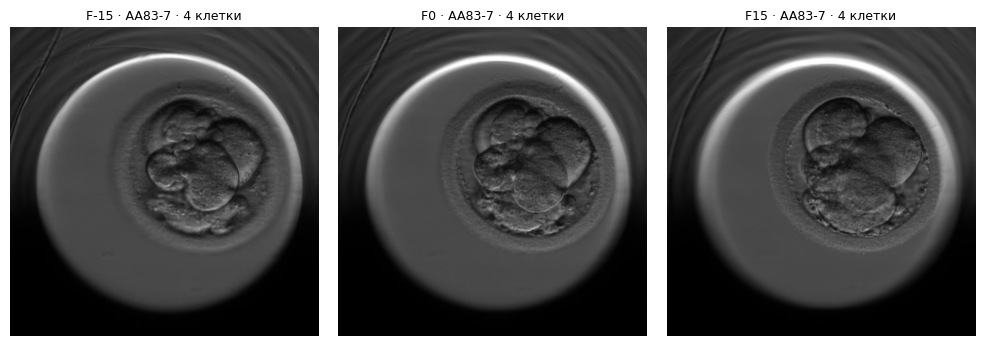

In [6]:
# Проверка ID пациенток: id = часть имени видео до дефиса
vpp = VID.groupby('patient').size()
print('примеры имён видео:', VID.video.sample(8, random_state=0).tolist())
print('видео на одну пациентку:', vpp.describe().round(1).to_dict())
print('пациенток с 1 видео:', int((vpp == 1).sum()), '| с 5+ видео:', int((vpp >= 5).sum()))
assert VID.video.str.contains('-').all(), 'Есть имена видео без дефиса — проверьте, как определяется пациентка!'

# Пример кадра в 3 фокусах
r = FR[FR.ok0 & FR.okm & FR.okp & (FR.label == PIDX['t4'])].iloc[0]
fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
for a, p, t in zip(ax, [r.pm, r.p0, r.pp], ['F-15', 'F0', 'F15']):
    a.imshow(Image.open(p).convert('L'), cmap='gray'); a.set_title(f'{t} · {r.video} · 4 клетки', fontsize=9); a.axis('off')
plt.tight_layout(); plt.show()

### Чистка
Убираем: битые/пустые кадры, почти пустые, точные копии предыдущего кадра, повтор времени. Если кадр битый только в F-15 или F15 — подставляем вместо него центральный F0 (кадр не теряем).

In [7]:
before = len(FR)
drop = (~FR.ok0) | (FR.std0 < 3) | dup_consec | dup_time | FR.hours.isna()
print('удаляем кадров:', int(drop.sum()), f'({drop.mean():.1%})')
FR = FR[~drop].reset_index(drop=True)
fb_m, fb_p = ~FR.okm, ~FR.okp
FR.loc[fb_m, 'pm'] = FR.loc[fb_m, 'p0']; FR.loc[fb_p, 'pp'] = FR.loc[fb_p, 'p0']
print(f'кадров осталось: {len(FR)} из {before} | подставлен F0 вместо F-15: {int(fb_m.sum())}, вместо F15: {int(fb_p.sum())}')
FR = FR[['video', 'frame', 'hours', 'label', 'p0', 'pm', 'pp']]
print('доля видео, дошедших до бластоцисты:', round(VID.blast.mean(), 3))
print(VID.groupby('blast').hours.describe().round(1))

удаляем кадров: 61803 (18.1%)
кадров осталось: 280560 из 342363 | подставлен F0 вместо F-15: 1731, вместо F15: 1714
доля видео, дошедших до бластоцисты: 0.741
       count   mean   std   min    25%    50%    75%    max
blast                                                      
False  182.0   86.1  20.1  46.1   70.5   75.0   95.0  142.4
True   522.0  126.8  13.2  93.9  118.5  120.0  140.7  167.3


## 4. Разделение по пациенткам
**Тест — те же 141 видео, что в v0.3** (тот же seed и тот же порядок видео) → результаты можно честно сравнивать с v0.3. Валидацию сделали больше (15% вместо 10%), чтобы выбор лучшей эпохи был надёжнее.

In [8]:
gss = GroupShuffleSplit(1, test_size=CFG['test_frac'], random_state=CFG['seed'])
trv, te = next(gss.split(VID, groups=VID.patient))
VID['split'] = 'train'; VID.loc[te, 'split'] = 'test'
trv_df = VID.iloc[trv]
gss2 = GroupShuffleSplit(1, test_size=CFG['val_frac'] / (1 - CFG['test_frac']), random_state=CFG['seed'])
_, va = next(gss2.split(trv_df, groups=trv_df.patient)); VID.loc[trv_df.index[va], 'split'] = 'val'
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    assert not set(VID[VID.split == a].patient) & set(VID[VID.split == b].patient), 'утечка пациенток!'
FR = FR.merge(VID[['video', 'split']], on='video')
print(VID.split.value_counts().to_dict())
old = glob.glob(os.path.join(CFG['data_root'], '**', 'split_by_video.csv'), recursive=True)
if old:
    o = pd.read_csv(old[0]); same = set(o[o.split == 'test'].video) == set(VID[VID.split == 'test'].video)
    print('тест совпадает с v0.3:', same)

{'train': 451, 'test': 141, 'val': 112}


## 5. Общие функции: HMM-склейка и метрики
**HMM-склейка.** Стадии идут только вперёд. По обучающим видео считаем, как часто стадия *k* переходит в *j* (с кадра на кадр). Так склейка «знает», что 2 клетки длятся часы, а не 15 минут, и что 2 → 4 (без 3) — нормально. Сила этого знания — параметр λ: λ = 0 — старая склейка из v0.3, λ подбираем на валидации.

**Метрики.** У нас три разных задачи, поэтому и метрики разные — так и должно быть:
| Задача | Тип | Метрики |
|---|---|---|
| Стадия на каждом кадре | классификация (15 классов) | accuracy, precision, recall, F1 (macro) |
| Время событий (t2, t5, tB…) в часах | регрессия | MAE, медиана ошибки, RMSE, R², доля ≤1 ч / ≤2 ч |
| Станет ли бластоцистой | бинарная классификация | AUROC |

In [9]:
def transition_logA(fr, k=K, alpha=1e-3):
    # log P(стадия j на следующем кадре | стадия i), только вперёд (j >= i)
    C = np.zeros((k, k))
    for _, g in fr[fr.label >= 0].groupby('video'):
        y = g.sort_values('frame').label.values
        for a, b in zip(y[:-1], y[1:]):
            if b >= a: C[a, b] += 1
    C += alpha * np.triu(np.ones((k, k)))
    A = C / C.sum(1, keepdims=True); up = np.triu(np.ones((k, k))) > 0
    return np.where(up, np.log(np.where(up, A, 1.0)), 0.0)

def viterbi(P, logA, lam=1.0, eps=1e-6):
    # лучшая НЕубывающая последовательность стадий; lam=0 -> как в v0.3
    L = np.log(P + eps); T_, k = L.shape
    forbid = np.where(np.triu(np.ones((k, k))) > 0, 0.0, -np.inf)
    trans = lam * logA + forbid
    D = L[0].copy(); B = np.zeros((T_, k), dtype=np.int16)
    for t in range(1, T_):
        S = D[:, None] + trans
        B[t] = S.argmax(0); D = S.max(0) + L[t]
    path = np.empty(T_, dtype=int); path[-1] = int(D.argmax())
    for t in range(T_ - 1, 0, -1): path[t - 1] = B[t, path[t]]
    return path

def events_from_path(path, hours):
    ev = {}
    for k in range(K):
        idx = np.flatnonzero(path == k)
        if len(idx): ev[PHASES[k]] = float(hours[idx[0]])
    return ev

def event_rows(pred_ev, vid_df, base=None, events=PHASES):
    # таблица (видео, событие, правда, предсказание, baseline)
    rows = []
    for _, r in vid_df.iterrows():
        pe = pred_ev.get(r.video, {})
        for e in events:
            rows.append(dict(video=r.video, event=e, true_h=r.events.get(e, np.nan), pred_h=pe.get(e, np.nan),
                             base_h=np.nan if base is None else base.get(e, np.nan)))
    return pd.DataFrame(rows)

def timing_summary(rows, col='pred_h', events=KEY, n_boot=0, seed=0):
    d = rows[rows.event.isin(events)]
    both = d[d.true_h.notna() & d[col].notna()].copy(); both['err'] = (both[col] - both.true_h).abs()
    r2 = [r2_score(g.true_h, g[col]) for _, g in both.groupby('event') if len(g) >= 5]
    out = dict(MAE_h=both.err.mean(), median_h=both.err.median(), RMSE_h=float(np.sqrt((both.err ** 2).mean())),
               R2=float(np.mean(r2)) if r2 else np.nan, within_1h=(both.err <= 1).mean(), within_2h=(both.err <= 2).mean(),
               found=(d.true_h.notna() & d[col].notna()).sum() / max(d.true_h.notna().sum(), 1),
               extra=(d.true_h.isna() & d[col].notna()).sum() / max(d[col].notna().sum(), 1))
    if n_boot:
        pv = both.groupby('video').err.mean().values; rng = np.random.default_rng(seed)
        bs = [pv[rng.integers(0, len(pv), len(pv))].mean() for _ in range(n_boot)]
        out['MAE_CI95'] = f'{np.percentile(bs, 2.5):.2f}–{np.percentile(bs, 97.5):.2f}'
    return out

def frame_metrics(y, p):
    m = y >= 0; y, p = y[m], p[m]
    return dict(accuracy=accuracy_score(y, p), precision=precision_score(y, p, average='macro', zero_division=0),
                recall=recall_score(y, p, average='macro', zero_division=0), macro_F1=f1_score(y, p, average='macro'))

LOGA = transition_logA(FR[FR.split == 'train'])
BASE = pd.DataFrame(list(VID[VID.split == 'train'].events)).median().to_dict()   # baseline: медианное время по train
print('вероятность перейти из t2 сразу в t4 (минуя t3), среди всех переходов из t2 в следующую стадию:',
      round(np.exp(LOGA[PIDX['t2'], PIDX['t4']]) / (1 - np.exp(LOGA[PIDX['t2'], PIDX['t2']])), 2))

вероятность перейти из t2 сразу в t4 (минуя t3), среди всех переходов из t2 в следующую стадию: 0.33


## 6. Модель 1: ConvNeXt-Tiny по кадру (3 фокуса)
**Почему ConvNeXt-Tiny:** современная CNN (2022), заметно точнее EfficientNet-B0 на мелких деталях, но всё ещё обучается на одной T4 за ~1 ч. Предобучена на ImageNet-22k.
Улучшения обучения: 10 эпох вместо 6, за 2 эпохи модель видит **все** кадры, EMA-усреднение весов (стабильнее), выбор лучшей эпохи по macro-F1 на большей валидации.

In [10]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225); S = CFG['img_size']
tf_train = T.Compose([T.Resize(int(S * 1.12)), T.RandomCrop(S), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                      T.RandomRotation(180), T.ColorJitter(0.2, 0.2), T.ToTensor(), T.Normalize(MEAN, STD)])
tf_eval = T.Compose([T.Resize(int(S * 1.12)), T.CenterCrop(S), T.ToTensor(), T.Normalize(MEAN, STD)])

def load_gray(p, size=None):
    im = Image.open(p); im.draft('L', (int(S * 1.2), int(S * 1.2))); im = im.convert('L')
    return im if size is None or im.size == size else im.resize(size)

class FrameDS(Dataset):
    # 3 канала = 3 фокуса одного кадра (F-15, F0, F15)
    def __init__(self, df, tf): self.p = df[['pm', 'p0', 'pp']].values; self.y = df.label.clip(lower=0).values; self.tf = tf
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        pm, p0, pp = self.p[i]; c = load_gray(p0)
        return self.tf(Image.merge('RGB', [load_gray(pm, c.size), c, load_gray(pp, c.size)])), int(self.y[i])

lab = FR[FR.label >= 0]
tr_all = lab[lab.split == 'train']; va_fr = lab[(lab.split == 'val') & (lab.frame % 2 == 0)]
cnt = tr_all.label.value_counts().reindex(range(K), fill_value=1).values
W = torch.tensor(np.clip((cnt.sum() / (K * cnt)) ** 0.5, None, 10.0), dtype=torch.float32, device=DEVICE)
crit = nn.CrossEntropyLoss(weight=W, label_smoothing=0.05)
print('кадров: train', len(tr_all), '(по половине за эпоху) | val', len(va_fr))

cnn = timm.create_model(CFG['backbone'], pretrained=True, num_classes=K).to(DEVICE).to(memory_format=torch.channels_last)
ema = timm.utils.ModelEmaV2(cnn, decay=0.999)
opt = torch.optim.AdamW(cnn.parameters(), lr=CFG['lr'], weight_decay=0.05)
steps_per_ep = len(tr_all) // CFG['train_every'] // CFG['batch_size']
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG['lr'], total_steps=CFG['epochs'] * steps_per_ep + 10, pct_start=0.1)
scaler = torch.amp.GradScaler('cuda', enabled=DEVICE == 'cuda')

@torch.no_grad()
def infer(model, df, bs=128, feats=False):
    # вероятности стадий (+ признаки кадра для BiGRU), с отражением (TTA)
    model.eval(); P, Fe = [], []
    dl = DataLoader(FrameDS(df, tf_eval), bs, num_workers=CFG['num_workers'], pin_memory=True)
    for x, _ in dl:
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        with torch.autocast('cuda', dtype=torch.float16, enabled=DEVICE == 'cuda'):
            f = (model.forward_head(model.forward_features(x), pre_logits=True) +
                 model.forward_head(model.forward_features(x.flip(-1)), pre_logits=True)) / 2
            lg = model.get_classifier()(f)
        P.append(F.softmax(lg.float(), 1).cpu())
        if feats: Fe.append(f.half().cpu())
    P = torch.cat(P).numpy()
    return (P, torch.cat(Fe).numpy()) if feats else P

CKPT = os.path.join(CFG['out_dir'], 'cnn_convnext_best.pt'); best, HIST = -1, []
for ep in range(CFG['epochs']):
    t0 = time.time(); cnn.train()
    sub = tr_all[tr_all.frame % CFG['train_every'] == ep % CFG['train_every']]
    dl = DataLoader(FrameDS(sub, tf_train), CFG['batch_size'], shuffle=True, num_workers=CFG['num_workers'], drop_last=True, pin_memory=True)
    for i, (x, y) in enumerate(dl):
        if i >= steps_per_ep: break
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last); y = y.to(DEVICE)
        with torch.autocast('cuda', dtype=torch.float16, enabled=DEVICE == 'cuda'):
            loss = crit(cnn(x), y)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
        scale = scaler.get_scale(); scaler.step(opt); scaler.update()
        if scaler.get_scale() >= scale: sched.step()        # шаг расписания только если шаг оптимизатора был (убирает warning)
        ema.update(cnn)
    P = infer(ema.module, va_fr); pr = P.argmax(1)
    m = frame_metrics(va_fr.label.values, pr); HIST.append(dict(epoch=ep + 1, **m))
    print(f"ep {ep+1} val acc {m['accuracy']:.3f} macro-F1 {m['macro_F1']:.3f} prec {m['precision']:.3f} rec {m['recall']:.3f} "
          f"{(time.time() - t0) / 60:.1f} мин" + (' *' if m['macro_F1'] > best else ''))
    if m['macro_F1'] > best: best = m['macro_F1']; torch.save(ema.module.state_dict(), CKPT)
cnn.load_state_dict(torch.load(CKPT, map_location=DEVICE)); cnn.eval()
pd.DataFrame(HIST).to_csv(os.path.join(CFG['out_dir'], 'cnn_training_history.csv'), index=False)
print('лучший val macro-F1:', round(best, 3))

кадров: train 171183 (по половине за эпоху) | val 23332


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

ep 1 val acc 0.635 macro-F1 0.523 prec 0.528 rec 0.541 9.6 мин *
ep 2 val acc 0.669 macro-F1 0.579 prec 0.573 rec 0.597 9.4 мин *
ep 3 val acc 0.672 macro-F1 0.587 prec 0.582 rec 0.601 9.3 мин *
ep 4 val acc 0.667 macro-F1 0.580 prec 0.575 rec 0.594 9.0 мин
ep 5 val acc 0.666 macro-F1 0.582 prec 0.579 rec 0.595 9.0 мин
ep 6 val acc 0.665 macro-F1 0.580 prec 0.574 rec 0.594 8.9 мин
ep 7 val acc 0.665 macro-F1 0.580 prec 0.576 rec 0.592 8.9 мин
ep 8 val acc 0.662 macro-F1 0.577 prec 0.574 rec 0.589 8.9 мин
ep 9 val acc 0.660 macro-F1 0.574 prec 0.571 rec 0.586 9.0 мин
ep 10 val acc 0.660 macro-F1 0.574 prec 0.572 rec 0.584 9.0 мин
лучший val macro-F1: 0.587


### Прогон по всем кадрам
Один проход лучшей модели по всем видео: получаем вероятности стадий (для Модели 1) и «описание» каждого кадра — вектор из 768 чисел (для Модели 2).

In [11]:
t0 = time.time()
FR = FR.sort_values(['video', 'frame']).reset_index(drop=True)
P_ALL, FEAT_ALL = infer(cnn, FR, feats=True)
print(f'готово за {(time.time() - t0) / 60:.1f} мин | признаки: {FEAT_ALL.shape}')
GIDX = {v: g.index.values for v, g in FR.groupby('video', sort=False)}
np.save(os.path.join(CFG['work'], 'feat_all.npy'), FEAT_ALL)

готово за 18.0 мин | признаки: (280560, 768)


## 7. Модель 2: ConvNeXt-Tiny + BiGRU (всё видео целиком)
ConvNeXt смотрит на один момент. **BiGRU** — рекуррентная сеть, которая читает последовательность описаний кадров **вперёд и назад** по всему видео (плюс время в часах). Так она видит контекст всех ~5 дней, а не 45 минут.
Чтобы BiGRU не «доверяла» слишком уверенным признакам с обучающих видео, во время обучения добавляем шум и dropout.

In [12]:
class SeqModel(nn.Module):
    def __init__(self, d_in, k, h=192):
        super().__init__()
        self.inp = nn.Sequential(nn.LayerNorm(d_in), nn.Dropout(0.3), nn.Linear(d_in, h), nn.GELU())
        self.gru = nn.GRU(h + 1, h, num_layers=2, batch_first=True, bidirectional=True, dropout=0.2)
        self.out = nn.Sequential(nn.Dropout(0.2), nn.Linear(2 * h, k))
    def forward(self, x, hrs, lens):
        if self.training: x = x + 0.1 * torch.randn_like(x)
        z = torch.cat([self.inp(x), (hrs / 100.0).unsqueeze(-1)], -1)
        pk = pack_padded_sequence(z, lens.cpu(), batch_first=True, enforce_sorted=False)
        y, _ = self.gru(pk); y, _ = pad_packed_sequence(y, batch_first=True, total_length=x.shape[1])
        return self.out(y)

def seq_batch(vs):
    xs = [torch.from_numpy(FEAT_ALL[GIDX[v]].astype(np.float32)) for v in vs]
    hs = [torch.tensor(FR.hours.values[GIDX[v]], dtype=torch.float32) for v in vs]
    ys = [torch.tensor(FR.label.values[GIDX[v]], dtype=torch.long).masked_fill(torch.tensor(FR.label.values[GIDX[v]] < 0), -100) for v in vs]
    lens = torch.tensor([len(x) for x in xs])
    return (pad_sequence(xs, True).to(DEVICE), pad_sequence(hs, True).to(DEVICE),
            pad_sequence(ys, True, padding_value=-100).to(DEVICE), lens)

@torch.no_grad()
def seq_predict(model, vs):
    model.eval(); out = {}
    for i in range(0, len(vs), 16):
        x, h, _, lens = seq_batch(vs[i:i + 16]); p = F.softmax(model(x, h, lens), -1).cpu().numpy()
        for j, v in enumerate(vs[i:i + 16]): out[v] = p[j, :lens[j]]
    return out

def probs_to_frames(pdict, vs):
    y = np.concatenate([FR.label.values[GIDX[v]] for v in vs]); p = np.concatenate([pdict[v].argmax(1) for v in vs])
    return y, p

V = {s: VID[VID.split == s].video.tolist() for s in ['train', 'val', 'test']}
seq = SeqModel(FEAT_ALL.shape[1], K).to(DEVICE)
opt2 = torch.optim.AdamW(seq.parameters(), lr=CFG['seq_lr'], weight_decay=1e-2)
sched2 = torch.optim.lr_scheduler.CosineAnnealingLR(opt2, CFG['seq_epochs'])
crit2 = nn.CrossEntropyLoss(weight=W, ignore_index=-100, label_smoothing=0.05)
SEQ_CKPT = os.path.join(CFG['out_dir'], 'seq_bigru_best.pt'); best2 = -1
for ep in range(CFG['seq_epochs']):
    seq.train(); vs = random.sample(V['train'], len(V['train']))
    for i in range(0, len(vs), 8):
        x, h, y, lens = seq_batch(vs[i:i + 8])
        loss = crit2(seq(x, h, lens).reshape(-1, K), y.reshape(-1))
        opt2.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(seq.parameters(), 1.0); opt2.step()
    sched2.step()
    y, p = probs_to_frames(seq_predict(seq, V['val']), V['val']); f1v = frame_metrics(y, p)['macro_F1']
    if f1v > best2: best2 = f1v; torch.save(seq.state_dict(), SEQ_CKPT)
    if (ep + 1) % 5 == 0: print(f'ep {ep+1} val macro-F1 {f1v:.3f} (лучший {best2:.3f})')
seq.load_state_dict(torch.load(SEQ_CKPT, map_location=DEVICE)); seq.eval()

ep 5 val macro-F1 0.606 (лучший 0.612)
ep 10 val macro-F1 0.602 (лучший 0.613)
ep 15 val macro-F1 0.606 (лучший 0.613)
ep 20 val macro-F1 0.609 (лучший 0.613)
ep 25 val macro-F1 0.605 (лучший 0.613)
ep 30 val macro-F1 0.602 (лучший 0.613)
ep 35 val macro-F1 0.602 (лучший 0.613)
ep 40 val macro-F1 0.603 (лучший 0.613)


SeqModel(
  (inp): Sequential(
    (0): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=768, out_features=192, bias=True)
    (3): GELU(approximate='none')
  )
  (gru): GRU(193, 192, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (out): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=384, out_features=15, bias=True)
  )
)

## 8. Подбор силы склейки λ на валидации и выбор лучшей модели
Всё подбираем **только на валидации** — тест не трогаем до финального сравнения.

In [13]:
PROBS = {'ConvNeXt': {v: P_ALL[GIDX[v]] for v in VID.video},
         'ConvNeXt+BiGRU': seq_predict(seq, VID.video.tolist())}

def decode_all(pdict, vs, lam):
    paths, evs = {}, {}
    for v in vs:
        h = FR.hours.values[GIDX[v]]; paths[v] = viterbi(pdict[v], LOGA, lam); evs[v] = events_from_path(paths[v], h)
    return paths, evs

TUNE, LAM = [], {}
for name, pdict in PROBS.items():
    for lam in CFG['lambdas']:
        _, ev = decode_all(pdict, V['val'], lam)
        s = timing_summary(event_rows(ev, VID[VID.split == 'val']))
        TUNE.append(dict(model=name, lam=lam, MAE_h=s['MAE_h'], found=s['found'], extra=s['extra']))
TUNE = pd.DataFrame(TUNE); display(TUNE.round(3))
for name in PROBS:
    t = TUNE[TUNE.model == name]; t = t[t.found >= t.found.max() - 0.03]     # не жертвуем находимостью событий
    LAM[name] = float(t.sort_values('MAE_h').lam.iloc[0])
print('выбранное λ:', LAM)
VAL_MAE = {n: TUNE[(TUNE.model == n) & (TUNE.lam == LAM[n])].MAE_h.iloc[0] for n in PROBS}
BEST = min(VAL_MAE, key=VAL_MAE.get); print('лучшая модель по валидации:', BEST, {k: round(v, 2) for k, v in VAL_MAE.items()})

,model,lam,MAE_h,found,extra
0,ConvNeXt,0.00,3.224,0.876,0.104
1,ConvNeXt,0.25,3.247,0.857,0.099
2,ConvNeXt,0.50,3.321,0.844,0.094
3,ConvNeXt,1.00,3.407,0.828,0.080
4,ConvNeXt,2.00,3.595,0.808,0.070
5,ConvNeXt+BiGRU,0.00,3.352,0.943,0.115
6,ConvNeXt+BiGRU,0.25,3.344,0.935,0.109
7,ConvNeXt+BiGRU,0.50,3.366,0.919,0.101
8,ConvNeXt+BiGRU,1.00,3.386,0.905,0.091
9,ConvNeXt+BiGRU,2.00,3.418,0.876,0.079


выбранное λ: {'ConvNeXt': 0.0, 'ConvNeXt+BiGRU': 0.25}
лучшая модель по валидации: ConvNeXt {'ConvNeXt': np.float64(3.22), 'ConvNeXt+BiGRU': np.float64(3.34)}


## 9. Финальное сравнение на тесте (141 видео, не участвовали ни в обучении, ни в подборе)
| Модель | Что это |
|---|---|
| Baseline | всегда «медианное время события по train» |
| EfficientNet-B0 (v0.3) | прошлая модель, цифры из прошлого запуска на **тех же** тестовых видео |
| ConvNeXt-Tiny, старая склейка | новая CNN + 3 фокуса, склейка как в v0.3 (λ = 0) |
| ConvNeXt-Tiny + HMM | то же + умная склейка |
| ConvNeXt-Tiny + BiGRU + HMM | + последовательная модель по всему видео |

In [14]:
test_vid = VID[VID.split == 'test']; COMP, DEC = [], {}
# Baseline
rows_b = event_rows({}, test_vid, base=BASE); s = timing_summary(rows_b, 'base_h', n_boot=CFG['n_boot']); s['found'], s['extra'] = 1.0, np.nan
COMP.append(dict(model='Baseline (медиана train)', **s))
# v0.3 — справочно, из прошлого запуска на тех же тестовых видео (16 классов)
COMP.append(dict(model='EfficientNet-B0 (v0.3, справочно)', accuracy=0.715, macro_F1=0.570, MAE_h=2.57, MAE_CI95='2.06–3.12',
                 within_1h=0.64, within_2h=0.74))
for name, lam, label in [('ConvNeXt', 0.0, 'ConvNeXt-Tiny, старая склейка'), ('ConvNeXt', LAM['ConvNeXt'], 'ConvNeXt-Tiny + HMM'),
                         ('ConvNeXt+BiGRU', LAM['ConvNeXt+BiGRU'], 'ConvNeXt-Tiny + BiGRU + HMM')]:
    paths, ev = decode_all(PROBS[name], V['test'], lam); DEC[label] = (paths, ev)
    y = np.concatenate([FR.label.values[GIDX[v]] for v in V['test']]); p = np.concatenate([paths[v] for v in V['test']])
    COMP.append(dict(model=label, **frame_metrics(y, p), **timing_summary(event_rows(ev, test_vid), n_boot=CFG['n_boot'])))
COMP = pd.DataFrame(COMP)[['model', 'accuracy', 'precision', 'recall', 'macro_F1', 'MAE_h', 'MAE_CI95', 'median_h',
                           'RMSE_h', 'R2', 'within_1h', 'within_2h', 'found', 'extra']]
display(COMP.round(3)); COMP.to_csv(os.path.join(CFG['out_dir'], 'model_comparison.csv'), index=False)
print('Время событий = ключевые события', KEY, '| R² = среднее по событиям | ДИ = 95% бутстрэп по видео')

,model,accuracy,precision,recall,macro_F1,MAE_h,MAE_CI95,median_h,RMSE_h,R2,within_1h,within_2h,found,extra
0,Baseline (медиана train),NaN,NaN,NaN,NaN,5.757,5.19–6.33,4.3,7.840,-0.012,0.135,0.262,1.000,NaN
1,"EfficientNet-B0 (v0.3, справочно)",0.715,NaN,NaN,0.570,2.570,2.06–3.12,NaN,NaN,NaN,0.640,0.740,NaN,NaN
2,"ConvNeXt-Tiny, старая склейка",0.752,0.658,0.658,0.651,2.205,1.77–2.82,0.5,4.918,0.564,0.677,0.761,0.864,0.119
3,ConvNeXt-Tiny + HMM,0.752,0.658,0.658,0.651,2.205,1.77–2.82,0.5,4.918,0.564,0.677,0.761,0.864,0.119
4,ConvNeXt-Tiny + BiGRU + HMM,0.761,0.673,0.679,0.674,2.298,1.92–3.25,0.5,5.358,0.392,0.666,0.765,0.910,0.129


Время событий = ключевые события ['t2', 't3', 't4', 't5', 't8', 'tSB', 'tB'] | R² = среднее по событиям | ДИ = 95% бутстрэп по видео


,n,MAE_h,median_h,RMSE_h,R2,within_1h,within_2h,found,extra,baseline_MAE_h
tPB2,125.0,2.50,2.30,2.70,-5.30,0.06,0.37,0.97,0.07,0.83
tPNa,135.0,1.39,1.00,2.22,-0.24,0.57,0.86,1.00,0.04,1.40
tPNf,140.0,0.57,0.20,1.65,0.74,0.91,0.92,0.95,0.01,2.65
t2,138.0,0.70,0.20,1.97,0.70,0.90,0.91,1.00,0.02,2.82
t3,88.0,1.66,0.20,3.95,0.50,0.78,0.82,0.77,0.31,4.14
t4,127.0,1.62,0.30,3.56,0.52,0.77,0.83,0.95,0.09,4.16
t5,105.0,3.22,0.50,6.64,0.27,0.66,0.71,0.65,0.21,5.69
t6,111.0,3.06,0.65,6.71,0.39,0.57,0.71,0.77,0.24,5.95
t7,96.0,4.07,1.00,7.72,0.39,0.52,0.62,0.64,0.30,6.89
t8,118.0,3.47,1.30,6.42,0.57,0.49,0.61,0.91,0.12,7.50


              precision    recall  f1-score   support

        tPB2      0.790     0.933     0.855      1766
        tPNa      0.970     0.926     0.947      8218
        tPNf      0.862     0.841     0.852      1245
          t2      0.915     0.903     0.909      5431
          t3      0.510     0.410     0.454       822
          t4      0.783     0.826     0.804      5172
          t5      0.469     0.217     0.296      1878
          t6      0.303     0.324     0.314      1313
          t7      0.292     0.247     0.267      2089
          t8      0.646     0.794     0.712      5429
         t9+      0.835     0.722     0.774      9813
          tM      0.575     0.733     0.644      2796
         tSB      0.703     0.793     0.745      2791
          tB      0.481     0.332     0.393      1469
         tEB      0.741     0.866     0.799      4051

    accuracy                          0.752     54283
   macro avg      0.658     0.658     0.651     54283
weighted avg      0.751   

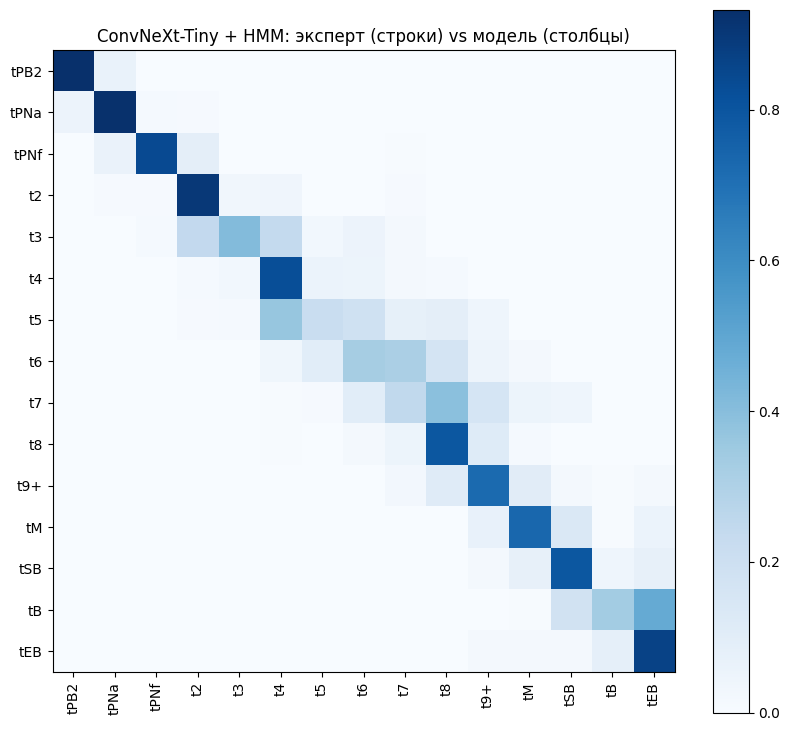

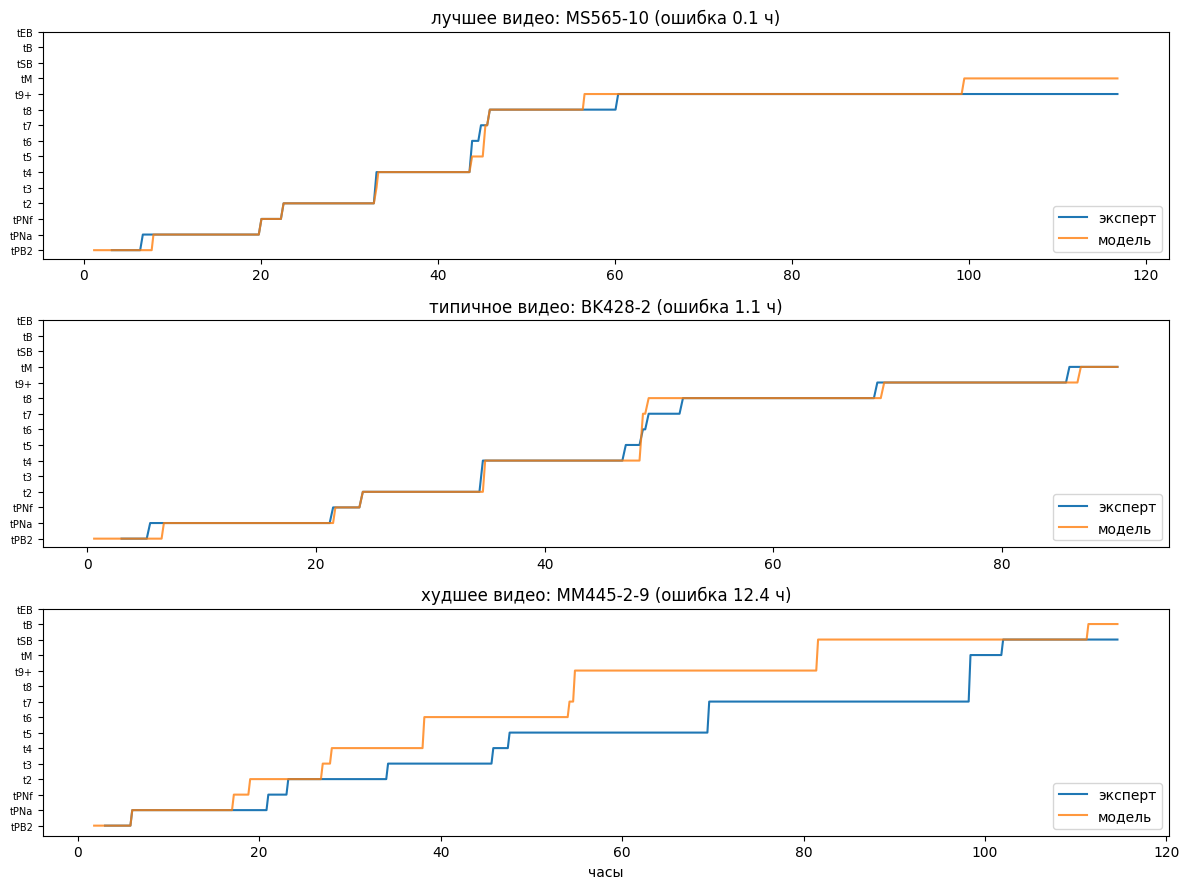

In [15]:
# Подробно по лучшей модели (выбрана по валидации)
BEST_LABEL = 'ConvNeXt-Tiny + BiGRU + HMM' if BEST == 'ConvNeXt+BiGRU' else 'ConvNeXt-Tiny + HMM'
paths, ev_best = DEC[BEST_LABEL]; rows = event_rows(ev_best, test_vid, base=BASE)
PER = pd.DataFrame({e: {**timing_summary(rows, events=[e]), 'baseline_MAE_h': timing_summary(rows, 'base_h', events=[e])['MAE_h'],
                        'n': int((rows.event.eq(e) & rows.true_h.notna()).sum())} for e in PHASES}).T
display(PER[['n', 'MAE_h', 'median_h', 'RMSE_h', 'R2', 'within_1h', 'within_2h', 'found', 'extra', 'baseline_MAE_h']].astype(float).round(2))
PER.to_csv(os.path.join(CFG['out_dir'], 'event_timing_errors.csv'))

y = np.concatenate([FR.label.values[GIDX[v]] for v in V['test']]); p = np.concatenate([paths[v] for v in V['test']]); m = y >= 0
print(classification_report(y[m], p[m], labels=range(K), target_names=PHASES, digits=3, zero_division=0))
cm = confusion_matrix(y[m], p[m], labels=range(K), normalize='true')
plt.figure(figsize=(8.5, 7.5)); plt.imshow(cm, cmap='Blues'); plt.xticks(range(K), PHASES, rotation=90); plt.yticks(range(K), PHASES)
plt.title(f'{BEST_LABEL}: эксперт (строки) vs модель (столбцы)'); plt.colorbar(); plt.tight_layout(); plt.show()

err = rows[rows.event.isin(KEY)].assign(e=lambda d: (d.pred_h - d.true_h).abs()).groupby('video').e.mean().dropna().sort_values()
fig, ax = plt.subplots(3, 1, figsize=(12, 9))
for a, v, nm in zip(ax, [err.index[0], err.index[len(err) // 2], err.index[-1]], ['лучшее', 'типичное', 'худшее']):
    g = FR.iloc[GIDX[v]]; a.plot(g.hours, g.label.where(g.label >= 0), label='эксперт'); a.plot(g.hours, paths[v], label='модель', alpha=.8)
    a.set_yticks(range(K), PHASES, fontsize=7); a.set_title(f'{nm} видео: {v} (ошибка {err[v]:.1f} ч)'); a.legend(loc='lower right')
ax[-1].set_xlabel('часы'); plt.tight_layout(); plt.show()

## 10. Нормы, поправка смещения и флаги
- **Нормы** (5–95 перцентиль) — по разметке экспертов на train-эмбрионах, ставших бластоцистами.
- **Поправка смещения:** на валидации смотрим, не сдвигает ли модель время систематически (например, всегда опаздывает на 0,5 ч). Этот сдвиг вычитаем перед сравнением с нормой → меньше ложных флагов.

In [16]:
def morpho(ev, until=None):
    e = {k: v for k, v in ev.items() if until is None or v <= until}
    g = lambda k: e.get(k, np.nan)
    f = {k: g(k) for k in ['t2', 't3', 't4', 't5', 't8']}
    f.update(cc2=g('t3') - g('t2'), s2=g('t4') - g('t3'), s3=g('t8') - g('t5'), t5_t2=g('t5') - g('t2'))
    f['stage_reached'] = max([PIDX[k] for k in e] or [-1])
    return f

REF = pd.DataFrame([morpho(ev) for ev in VID[(VID.split == 'train') & VID.blast].events]).drop(columns='stage_reached').quantile([.05, .95]).T
REF.columns = ['p05', 'p95']; display(REF.round(1))

_, ev_val = decode_all(PROBS[BEST], V['val'], LAM[BEST])
rv = event_rows(ev_val, VID[VID.split == 'val'])
BIAS = rv.dropna(subset=['true_h', 'pred_h']).assign(d=lambda x: x.pred_h - x.true_h).groupby('event').d.median().reindex(PHASES).fillna(0)
print('систематический сдвиг модели (ч, + = опаздывает):'); print(BIAS[['t2', 't3', 't4', 't5', 't8', 'tSB', 'tB']].round(2).to_dict())
def correct(ev): return {k: v - BIAS.get(k, 0.0) for k, v in ev.items()}

def flags(f):
    out = []
    for k, (lo, hi) in REF.iterrows():
        v = f.get(k, np.nan)
        if pd.notna(v) and (v < lo or v > hi): out.append(f'{k} = {v:.1f} ч вне нормы ({lo:.1f}–{hi:.1f} ч)')
    if pd.notna(f.get('cc2')) and f['cc2'] < 5: out.append('возможное прямое деление 2→3 клетки (t3 − t2 < 5 ч)')
    return out

,p05,p95
t2,22.5,35.0
t3,28.4,47.8
t4,33.8,50.0
t5,38.0,61.0
t8,47.3,81.0
cc2,1.5,14.0
s2,0.5,12.0
s3,1.4,26.3
t5_t2,11.7,30.9


систематический сдвиг модели (ч, + = опаздывает):
{'t2': 0.0, 't3': 0.0, 't4': -0.3, 't5': 0.2, 't8': -0.5, 'tSB': -0.5, 'tB': 0.0}


## 11. (Исследовательски) прогноз бластоцисты по первым 72 ч
Сравниваем 2 модели: **логистическая регрессия** (простая, устойчивая на малых данных) и **градиентный бустинг**. Оценка — повторная кросс-валидация по пациенткам (5 фолдов × 5 повторов) на train+val, на тесте — по таймингам модели с 95% ДИ.
Вместо «голой» вероятности (она почти всегда ~0,95, потому что 96% эмбрионов здесь — бластоцисты) выдаём **ранг**: насколько эмбрион выше/ниже других.

In [17]:
lab_v = VID[VID.blast | (VID.hours >= CFG['observe_hours'])].copy()
X_gt = pd.DataFrame([morpho(ev, CFG['early_hours']) for ev in lab_v.events], index=lab_v.index)
print(f'видео: {len(lab_v)}, из них «не бластоциста» (наблюдались ≥{CFG["observe_hours"]} ч): {int((~lab_v.blast).sum())}')
fit_m = lab_v.split != 'test'; Xf, yf, gf = X_gt[fit_m], lab_v.blast[fit_m].astype(int), lab_v.patient[fit_m]
CANDS = {'LogReg': make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(),
                                 LogisticRegression(C=0.3, class_weight='balanced', max_iter=2000)),
         'Boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, class_weight='balanced', random_state=0)}
CV = {}
for nm, mdl in CANDS.items():
    aucs = []
    for s in range(5):
        for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(Xf, yf, gf):
            if yf.iloc[b].nunique() == 2:
                aucs.append(roc_auc_score(yf.iloc[b], copy.deepcopy(mdl).fit(Xf.iloc[a], yf.iloc[a]).predict_proba(Xf.iloc[b])[:, 1]))
    CV[nm] = (np.mean(aucs), np.std(aucs)); print(f'{nm}: CV AUROC {np.mean(aucs):.3f} ± {np.std(aucs):.3f}')
BL = max(CV, key=lambda k: CV[k][0]); clf = copy.deepcopy(CANDS[BL]).fit(Xf, yf); print('выбрана:', BL)
TRAIN_SCORES = np.sort(clf.predict_proba(Xf)[:, 1])
def rank(s): return float(np.searchsorted(TRAIN_SCORES, s) / len(TRAIN_SCORES))

te_v = lab_v[~fit_m]
_, ev_te = decode_all(PROBS[BEST], te_v.video.tolist(), LAM[BEST])
X_te = pd.DataFrame([morpho(correct(ev_te[v]), CFG['early_hours']) for v in te_v.video], index=te_v.index)
yt, st = te_v.blast.astype(int).values, clf.predict_proba(X_te)[:, 1]
if len(set(yt)) == 2:
    rng = np.random.default_rng(0); bs = []
    for _ in range(CFG['n_boot']):
        i = rng.integers(0, len(yt), len(yt))
        if len(set(yt[i])) == 2: bs.append(roc_auc_score(yt[i], st[i]))
    print(f'AUROC на тесте (тайминги модели): {roc_auc_score(yt, st):.3f}, 95% ДИ {np.percentile(bs, 2.5):.2f}–{np.percentile(bs, 97.5):.2f} '
          f'| n={len(yt)}, отрицательных={int((yt == 0).sum())}')
print('⚠️ Отрицательных примеров очень мало — широкий ДИ это честно показывает. Нужны данные клиники.')

видео: 544, из них «не бластоциста» (наблюдались ≥110 ч): 22
LogReg: CV AUROC 0.616 ± 0.152
Boosting: CV AUROC 0.581 ± 0.202
выбрана: LogReg
AUROC на тесте (тайминги модели): 0.773, 95% ДИ 0.48–0.98 | n=111, отрицательных=6
⚠️ Отрицательных примеров очень мало — широкий ДИ это честно показывает. Нужны данные клиники.


## 12. Функция для платформы: видео → JSON

In [18]:
@torch.no_grad()
def analyze_embryo(frame_paths, hours, paths_m=None, paths_p=None):
    # frame_paths: кадры центрального фокуса по порядку; paths_m/paths_p: F-15/F15 (если нет — берём центральный); hours: время кадров
    df = pd.DataFrame({'p0': frame_paths, 'pm': paths_m or frame_paths, 'pp': paths_p or frame_paths, 'label': 0})
    P, Fe = infer(cnn, df, feats=True); hrs = np.asarray(hours, dtype=float)
    if BEST == 'ConvNeXt+BiGRU':
        x = torch.from_numpy(Fe.astype(np.float32))[None].to(DEVICE); h = torch.tensor(hrs, dtype=torch.float32)[None].to(DEVICE)
        P = F.softmax(seq(x, h, torch.tensor([len(hrs)])), -1)[0].cpu().numpy()
    path = viterbi(P, LOGA, LAM[BEST]); ev = correct(events_from_path(path, hrs))
    f_all, f_early = morpho(ev), morpho(ev, CFG['early_hours']); fl = flags(f_all)
    conf = float(np.mean(P[np.arange(len(path)), path])); warn = []
    if len(frame_paths) < 100: warn.append('мало кадров')
    if hrs.max() < CFG['early_hours']: warn.append('видео короче 72 ч — прогноз бластоцисты недоступен')
    if conf < 0.6: warn.append('низкая уверенность распознавания стадий')
    score = None if hrs.max() < CFG['early_hours'] else float(clf.predict_proba(pd.DataFrame([f_early])[Xf.columns])[0, 1])
    r = None if score is None else rank(score)
    if fl and r is not None and r > 0.5: warn.append('есть отклонения морфокинетики при среднем/высоком ранге — интерпретировать осторожно')
    return {'model_version': CFG['model_version'], 'model': BEST_LABEL, 'task': 'timelapse_morphokinetics',
            'events_hours': {k: round(v, 1) for k, v in ev.items()},
            'morphokinetics': {k: (None if pd.isna(v) else round(float(v), 1)) for k, v in f_all.items() if k != 'stage_reached'},
            'last_stage': PHASES[int(path[-1])], 'flags': fl, 'stage_confidence': round(conf, 3),
            'blastocyst_rank_research': None if r is None else round(r, 2),
            'blastocyst_rank_meaning': 'доля эмбрионов из обучения с более низким баллом (0 — хуже всех, 1 — лучше всех)',
            'status': 'no_recommendation' if warn else 'ok', 'warnings': warn,
            'disclaimer': 'Только для исследования и проверки эмбриологом. Не является клиническим решением.'}

v = V['test'][0]; g = FR.iloc[GIDX[v]]
print(json.dumps(analyze_embryo(g.p0.tolist(), g.hours.tolist(), g.pm.tolist(), g.pp.tolist()), ensure_ascii=False, indent=2))

{
  "model_version": "timelapse-v0.4",
  "model": "ConvNeXt-Tiny + HMM",
  "task": "timelapse_morphokinetics",
  "events_hours": {
    "tPB2": 3.7,
    "tPNa": 8.0,
    "tPNf": 23.6,
    "t2": 25.7,
    "t3": 44.4,
    "t4": 45.0,
    "t5": 47.2,
    "t6": 48.0,
    "t8": 60.7,
    "t9+": 68.0
  },
  "morphokinetics": {
    "t2": 25.7,
    "t3": 44.4,
    "t4": 45.0,
    "t5": 47.2,
    "t8": 60.7,
    "cc2": 18.7,
    "s2": 0.6,
    "s3": 13.5,
    "t5_t2": 21.5
  },
  "last_stage": "t9+",
  "flags": [
    "cc2 = 18.7 ч вне нормы (1.5–14.0 ч)"
  ],
  "stage_confidence": 0.679,
  "blastocyst_rank_research": 0.7,
  "blastocyst_rank_meaning": "доля эмбрионов из обучения с более низким баллом (0 — хуже всех, 1 — лучше всех)",
  "status": "no_recommendation",
  "warnings": [
    "есть отклонения морфокинетики при среднем/высоком ранге — интерпретировать осторожно"
  ],
  "disclaimer": "Только для исследования и проверки эмбриологом. Не является клиническим решением."
}


## 13. Сохранение артефактов для платформы

In [19]:
import joblib
joblib.dump(clf, os.path.join(CFG['out_dir'], 'blastocyst_clf_research.joblib'))
np.save(os.path.join(CFG['out_dir'], 'hmm_logA.npy'), LOGA)
REF.to_json(os.path.join(CFG['out_dir'], 'morphokinetic_reference.json'), orient='index', indent=2)
BIAS.to_json(os.path.join(CFG['out_dir'], 'timing_bias_correction.json'), indent=2)
json.dump({**CFG, 'phases': PHASES, 'key_events': KEY, 'best_model': BEST_LABEL, 'lambda': LAM, 'blast_model': BL,
           'split_counts': VID.split.value_counts().to_dict()},
          open(os.path.join(CFG['out_dir'], 'config_timelapse.json'), 'w'), ensure_ascii=False, indent=2, default=str)
VID[['video', 'patient', 'split']].to_csv(os.path.join(CFG['out_dir'], 'split_by_video.csv'), index=False)
pd.DataFrame([{'video': v, **e} for v, e in ev_best.items()]).to_csv(os.path.join(CFG['out_dir'], 'test_predicted_events.csv'), index=False)
print(sorted(os.listdir(CFG['out_dir'])))

['__notebook__.ipynb', 'audit_archives.csv', 'audit_frames.csv', 'blastocyst_clf_research.joblib', 'cnn_convnext_best.pt', 'cnn_training_history.csv', 'config_timelapse.json', 'event_timing_errors.csv', 'hmm_logA.npy', 'model_comparison.csv', 'morphokinetic_reference.json', 'seq_bigru_best.pt', 'split_by_video.csv', 'test_predicted_events.csv', 'timing_bias_correction.json']


## 14. Что исправлено (по списку проблем)
| # | Проблема | Что сделано |
|---|---|---|
| 1 | 25 732 битых кадра | Аудит оригинала (md5 + файлы внутри архива), чистая распаковка, полная проверка всех кадров |
| 2 | 83 почти пустых кадра | Удаляются |
| 3 | Разметка не с первого кадра | Считаются отдельно; tPB2/tPNa не входят в главную метрику |
| 4 | «Не бластоциста» = короткое видео | Учтено (≥110 ч), признаки только до 72 ч |
| 5 | Повтор времени | Такие кадры удаляются |
| 6 | Дубликаты не проверялись | md5 содержимого: копии подряд удаляются, копии в разных видео выводятся |
| 7 | tHB 5 раз | Объединена с tEB (15 стадий) |
| 8 | Одна клиника | Кодом не исправить — нужна проверка на данных Persona |
| 9 | Лицензия NC | Кодом не исправить — только исследование/демо |
| 10 | Один фокус | 3 фокуса (F-15, F0, F15) как 3 канала |
| 11–12 | Низкий F1, лучшая эпоха — 2-я | ConvNeXt-Tiny, 10 эпох, все кадры, EMA |
| 13 | Маленькая валидация | 15% вместо 10% (тест не изменился) |
| 14 | Мало контекста | BiGRU по всему видео |
| 15–17, 22 | Путаница 5–8, лишние t3, перескоки | 3 фокуса + BiGRU + HMM-склейка с выученными переходами |
| 18 | tPB2/tPNa хуже baseline | Объяснено (разметка не с начала), вынесено из главной метрики |
| 20 | Ложная tHB | Класс объединён |
| 23–24 | Слабый прогноз, мало примеров | 2 модели, повторная CV, ДИ на тесте; честно помечено как исследовательское |
| 25 | Обучение на разметке, применение к модели | Поправка систематического сдвига модели |
| 26 | Флаг + 99,6% | Ранг вместо вероятности + предупреждение при противоречии |
| 27 | Нормы vs предсказания | Поправка смещения перед флагами |
| 28 | Неверный комментарий | Исправлено |
| 29 | Warning scheduler | Шаг расписания только после шага оптимизатора |
| 30 | ID пациентки | Проверка формата имён + отчёт о числе видео на пациентку |